In [1]:

# ============================================================
# APPLIED STATISTICS PROJECT
# AIR QUALITY ANALYSIS - DATA COMBINATION AND CLEANING
# ============================================================

# STEP 1: IMPORT LIBRARIES

import pandas as pd
import numpy as np
import os
from IPython.display import display

# ============================================================
# STEP 2: PROJECT PATHS (relative to the repository)
# ============================================================

# This notebook lives in notebooks/, so the project root is one level up.
PROJECT_DIR = os.path.abspath('..')

RAW_DIR = os.path.join(PROJECT_DIR, 'data', 'raw')
OUTPUT_DIR = os.path.join(PROJECT_DIR, 'data', 'clean')

# Create output folder if it doesn't exist
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ============================================================
# STEP 3: LOAD RAW DATA
# ============================================================

files = {
    'Gujarat': 'cpcb_dly_aq_gujarat-2015.csv',
    'Odisha': 'cpcb_dly_aq_odisha-2015.csv',
    'West Bengal': 'cpcb_dly_aq_west_bengal-2015.csv'
}

dataframes = []

for state, filename in files.items():

    filepath = os.path.join(RAW_DIR, filename)

    if not os.path.exists(filepath):
        raise FileNotFoundError(
            f"Could not find {filename}. "
            f"Please check the raw-data folder."
        )

    df = pd.read_csv(filepath, encoding='cp1252')

    # Remove completely empty columns
    df = df.dropna(axis=1, how='all')

    # Standardise column names
    df.columns = df.columns.str.strip()

    # Remove extra whitespace from text columns
    for col in df.select_dtypes(include='object').columns:
        df[col] = df[col].str.strip()

    dataframes.append(df)

    print(f"{state}: {len(df)} records loaded")

# ============================================================
# STEP 4: COMBINE DATASETS
# ============================================================

master_df = pd.concat(dataframes, ignore_index=True)

print("\nCombined records:", len(master_df))

# ============================================================
# STEP 5: STANDARDISE DATA
# ============================================================

# Standardise state names
master_df['State'] = master_df['State'].str.strip()

# Standardise city names for consistent grouping
master_df['City/Town/Village/Area'] = (
    master_df['City/Town/Village/Area']
    .str.strip()
    .str.upper()
)

# Convert sampling dates
master_df['Sampling Date'] = pd.to_datetime(
    master_df['Sampling Date'],
    format='%d-%m-%y',
    errors='coerce'
)

invalid_dates = master_df['Sampling Date'].isna().sum()

print("Invalid dates:", invalid_dates)

# Convert pollutant columns to numeric
pollutant_columns = [
    'SO2',
    'NO2',
    'RSPM/PM10',
    'PM 2.5'
]

for col in pollutant_columns:
    master_df[col] = pd.to_numeric(
        master_df[col],
        errors='coerce'
    )

# Treat negative pollutant readings as invalid
for col in pollutant_columns:
    master_df.loc[master_df[col] < 0, col] = np.nan

# ============================================================
# STEP 6: CREATE UNIQUE STATION IDENTIFIER
# ============================================================

master_df['Station_ID'] = (
    master_df['State'].astype(str) + '_' +
    master_df['Stn Code'].astype(str) + '_' +
    master_df['Location of Monitoring Station'].astype(str)
)

# ============================================================
# STEP 7: CHECK DUPLICATE RECORDS
# ============================================================

duplicate_columns = [
    'State',
    'Station_ID',
    'Sampling Date'
]

duplicate_count = master_df.duplicated(
    subset=duplicate_columns
).sum()

print("Duplicate station-date records:", duplicate_count)

# Duplicates are reported but not automatically removed.
# Multiple records may need investigation before deletion.

# ============================================================
# STEP 8: SAVE MASTER DATASET
# ============================================================

master_path = os.path.join(
    OUTPUT_DIR,
    'air_quality_master.csv'
)

master_df.to_csv(master_path, index=False)

print("\nMaster dataset saved.")

# ============================================================
# STEP 9: CREATE COMPLETE-CASE DATASET
# ============================================================

# Retain observations with all four pollutant measurements
final_df = master_df.dropna(
    subset=pollutant_columns
).copy()

excluded_records = len(master_df) - len(final_df)

print("\nComplete-case records:", len(final_df))
print("Records excluded:", excluded_records)

# Save final dataset
final_path = os.path.join(
    OUTPUT_DIR,
    'air_quality_final.csv'
)

final_df.to_csv(final_path, index=False)

# ============================================================
# STEP 10: GENERATE CLEANING SUMMARY
# ============================================================

summary = master_df.groupby('State').apply(
    lambda group: pd.Series({
        'Total_Records': len(group),
        'Unique_Cities': group[
            'City/Town/Village/Area'
        ].nunique(),
        'Unique_Stations': group['Station_ID'].nunique(),
        'Complete_Records': group[
            pollutant_columns
        ].notna().all(axis=1).sum(),
        'Incomplete_Records': group[
            pollutant_columns
        ].isna().any(axis=1).sum(),
        'Complete_Percentage': round(
            group[pollutant_columns]
            .notna()
            .all(axis=1)
            .mean() * 100,
            2
        )
    })
).reset_index()

print("\nCLEANING SUMMARY")
display(summary)

summary_path = os.path.join(
    OUTPUT_DIR,
    'cleaning_summary.csv'
)

summary.to_csv(summary_path, index=False)

# ============================================================
# STEP 11: CHECK FINAL DATASET
# ============================================================

print("\nFINAL DATASET SHAPE:", final_df.shape)

print("\nMISSING VALUES IN FINAL DATASET:")
print(final_df[pollutant_columns].isna().sum())

print("\nRECORDS BY STATE IN FINAL DATASET:")
print(final_df['State'].value_counts())

print("\nUNIQUE CITIES IN FINAL DATASET:")
print(
    final_df.groupby('State')[
        'City/Town/Village/Area'
    ].nunique()
)

print("\nDATE RANGE:")
print("Start:", final_df['Sampling Date'].min())
print("End:", final_df['Sampling Date'].max())

# ============================================================
# STEP 12: GENERATE CLEANING LOG
# ============================================================

cleaning_log = pd.DataFrame({
    'Step': [
        'Raw data loaded',
        'Datasets combined',
        'Empty columns removed',
        'Text fields trimmed',
        'City names standardised',
        'Sampling dates converted',
        'Negative pollutant readings set to missing',
        'Complete-case filtering'
    ],
    'Details': [
        'Loaded three state-wise CPCB CSV files',
        f'{len(master_df)} records combined',
        'Completely empty columns removed from source files',
        'Leading and trailing whitespace removed',
        'City names converted to uppercase for consistent grouping',
        f'{invalid_dates} invalid dates found',
        'Negative pollutant values replaced with missing values',
        f'{excluded_records} incomplete records excluded; '
        f'{len(final_df)} records retained'
    ]
})

log_path = os.path.join(
    OUTPUT_DIR,
    'cleaning_log.csv'
)

cleaning_log.to_csv(log_path, index=False)

# ============================================================
# STEP 13: FINAL OUTPUT
# ============================================================

print("\n" + "="*55)
print("DATA PROCESSING COMPLETED SUCCESSFULLY")
print("="*55)

print("\nFiles saved in:", OUTPUT_DIR)

print("\nGenerated files:")
print("1. air_quality_master.csv")
print("2. air_quality_final.csv")
print("3. cleaning_summary.csv")
print("4. cleaning_log.csv")

print("\nAll outputs are saved to data/clean/ in the repository.")


Gujarat: 1081 records loaded
Odisha: 2392 records loaded
West Bengal: 2497 records loaded

Combined records: 5970
Invalid dates: 0
Duplicate station-date records: 0

Master dataset saved.

Complete-case records: 3778
Records excluded: 2192

CLEANING SUMMARY


C:\Users\Advay\AppData\Local\Temp\ipykernel_19136\3565609515.py:57: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:
C:\Users\Advay\AppData\Local\Temp\ipykernel_19136\3565609515.py:57: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guid

,State,Total_Records,Unique_Cities,Unique_Stations,Complete_Records,Incomplete_Records,Complete_Percentage
0,Gujarat,1081.0,12.0,32.0,1080.0,1.0,99.91
1,Odisha,2392.0,14.0,32.0,2060.0,332.0,86.12
2,West Bengal,2497.0,13.0,25.0,638.0,1859.0,25.55



FINAL DATASET SHAPE: (3778, 12)

MISSING VALUES IN FINAL DATASET:
SO2          0
NO2          0
RSPM/PM10    0
PM 2.5       0
dtype: int64

RECORDS BY STATE IN FINAL DATASET:
State
Odisha         2060
Gujarat        1080
West Bengal     638
Name: count, dtype: int64

UNIQUE CITIES IN FINAL DATASET:
State
Gujarat        12
Odisha         14
West Bengal     4
Name: City/Town/Village/Area, dtype: int64

DATE RANGE:
Start: 2015-01-01 00:00:00
End: 2015-12-31 00:00:00

DATA PROCESSING COMPLETED SUCCESSFULLY

Files saved in: C:\Users\Advay\Desktop\ASM\Asm project\data\clean

Generated files:
1. air_quality_master.csv
2. air_quality_final.csv
3. cleaning_summary.csv
4. cleaning_log.csv

All outputs are saved to data/clean/ in the repository.


CITY-WISE OBSERVATIONS IN FINAL DATASET


,State,City/Town/Village/Area,Observations
10,Gujarat,VADODARA,254
0,Gujarat,AHMEDABAD,230
1,Gujarat,ANKLESHWAR,215
9,Gujarat,SURAT,72
11,Gujarat,VAPI,72
2,Gujarat,BHARUCH,48
6,Gujarat,RAJKOT,48
5,Gujarat,MORBI,46
3,Gujarat,BHUJ,24
4,Gujarat,JAMNAGAR,24


STATION-WISE OBSERVATIONS


,State,Station_ID,Observations
28,Gujarat,Gujarat_SAMP_Panoli Ind.Asso. & Emergency Resp...,84
26,Gujarat,"Gujarat_SAMP_GIDC OFFICE TERRACE, GIDC ESTATE ...",83
18,Gujarat,"Gujarat_50_GPCB Office, Geri Vasahat, Vadodara",65
13,Gujarat,"Gujarat_333_Dandia Bazaar, Vadodara",63
14,Gujarat,"Gujarat_334_CETP Nandesari, Vadodara",63
...,...,...,...
70,West Bengal,West Bengal_SAMP_Rooftop of Shyambazar Tennis ...,104
68,West Bengal,"West Bengal_476_Behala Chowrasta,Kolkata",103
65,West Bengal,"West Bengal_385_PCBL Club, Biddhanagar, Durgapur",102
66,West Bengal,"West Bengal_473_Moulali, Kolkata",61


MISSING VALUES BY STATE (%)


,SO2,NO2,RSPM/PM10,PM 2.5
State,,,,
Gujarat,0.09,0.09,0.09,0.09
Odisha,0.00,0.00,0.00,13.88
West Bengal,0.28,0.28,0.04,74.37


... (2 outputs left out)

OVERALL DESCRIPTIVE STATISTICS


,SO2,NO2,RSPM/PM10,PM 2.5
count,3778.00,3778.00,3778.00,3778.00
mean,8.15,24.04,92.96,43.01
std,5.93,13.97,40.12,25.24
min,2.00,5.00,15.00,5.00
25%,2.00,16.00,73.00,29.00
50%,7.00,21.00,86.50,36.00
75%,13.00,26.00,104.00,49.00
max,84.00,125.00,590.00,331.00


DATE COVERAGE


,Start_Date,End_Date,Unique_Dates
State,,,
Gujarat,2015-01-02,2015-12-31,248
Odisha,2015-01-01,2015-12-31,307
West Bengal,2015-01-02,2015-12-30,336


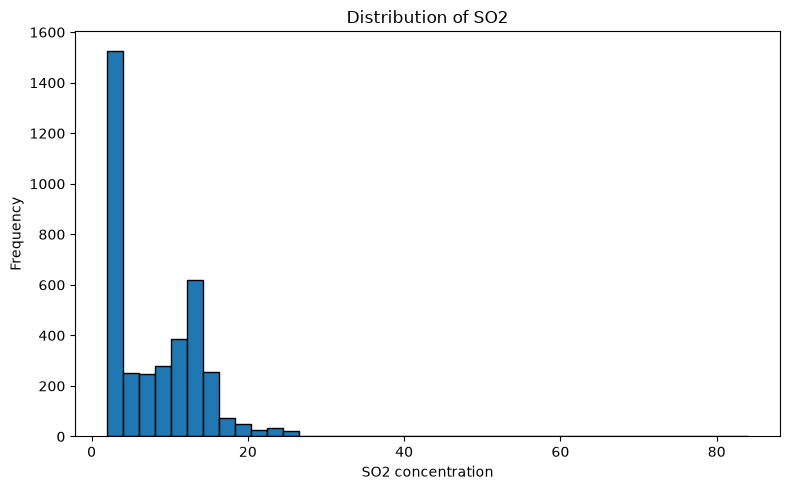

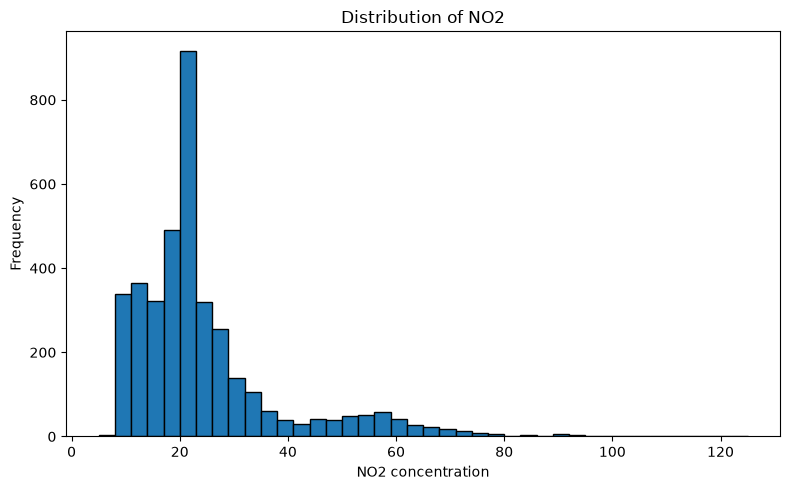

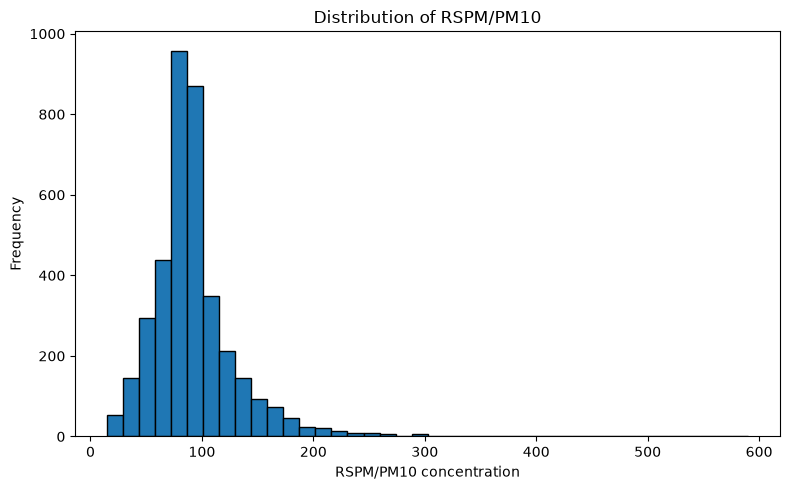

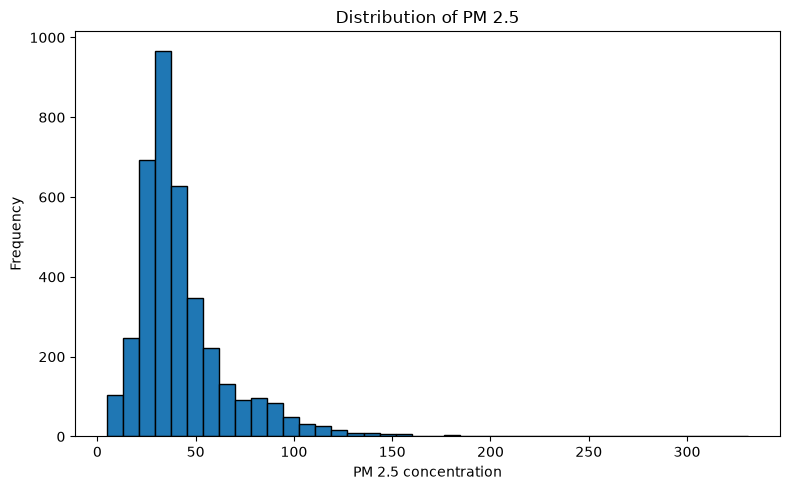

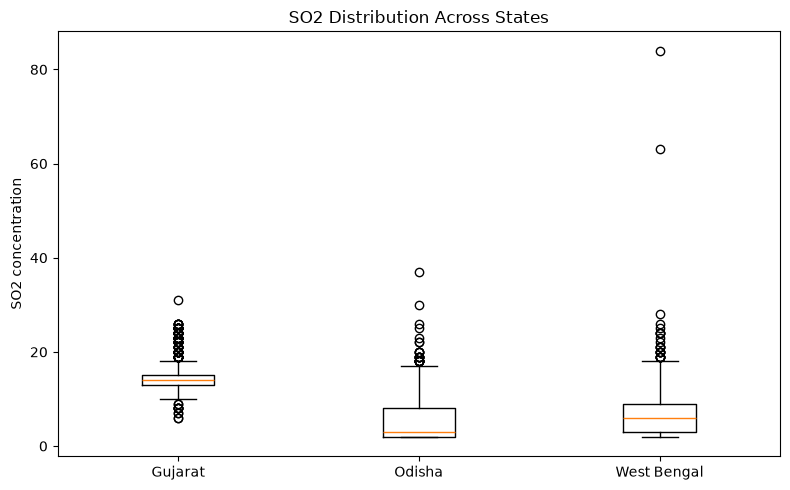

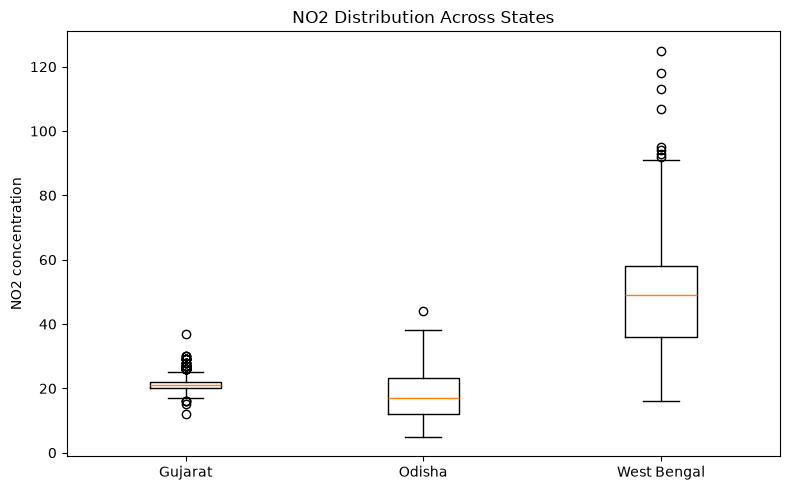

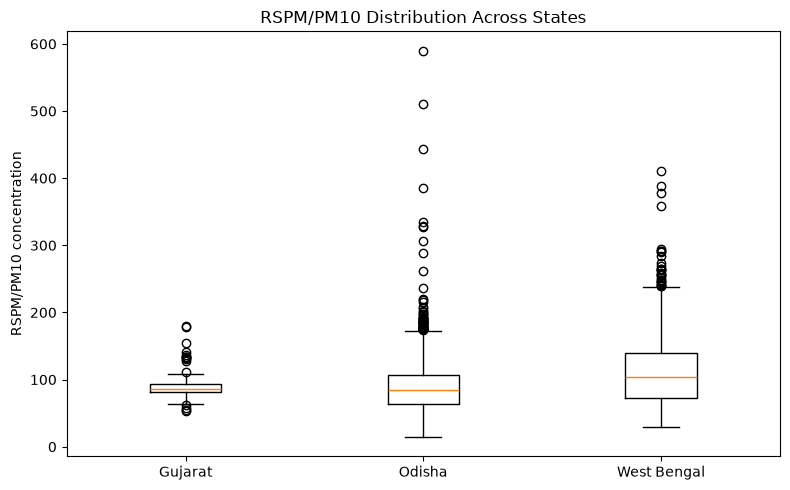

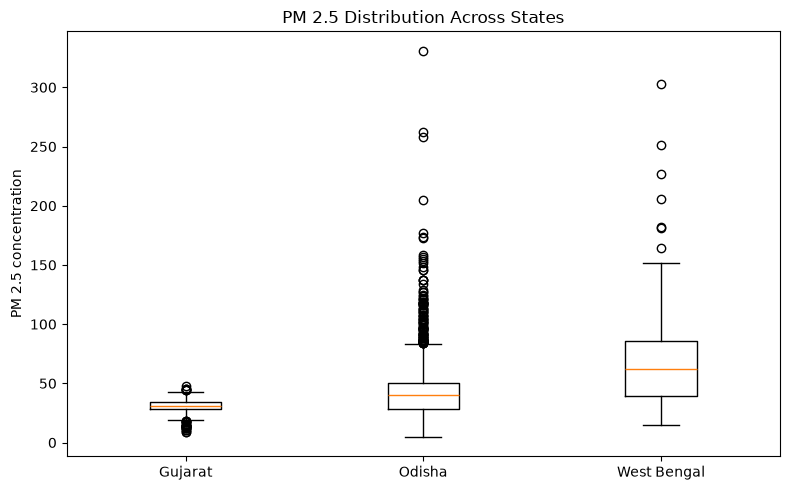

VALIDATION AND EDA OUTPUTS GENERATED.


In [2]:

import pandas as pd
import numpy as np
import os
from IPython.display import display
import matplotlib.pyplot as plt

PROJECT_DIR = os.path.abspath('..')
OUTPUT_DIR = os.path.join(PROJECT_DIR, 'data', 'clean')

master = pd.read_csv(
    os.path.join(OUTPUT_DIR, 'air_quality_master.csv')
)

df = pd.read_csv(
    os.path.join(OUTPUT_DIR, 'air_quality_final.csv')
)

pollutants = ['SO2', 'NO2', 'RSPM/PM10', 'PM 2.5']

# ------------------------------------------------
# 1. CITY-WISE SAMPLE SIZES
# ------------------------------------------------

city_counts = (
    df.groupby(['State', 'City/Town/Village/Area'])
      .size()
      .reset_index(name='Observations')
      .sort_values(['State', 'Observations'], ascending=[True, False])
)

print("CITY-WISE OBSERVATIONS IN FINAL DATASET")
display(city_counts)

city_counts.to_csv(
    os.path.join(OUTPUT_DIR, 'city_sample_counts.csv'),
    index=False
)

# ------------------------------------------------
# 2. STATION-WISE SAMPLE SIZES
# ------------------------------------------------

station_counts = (
    df.groupby(['State', 'Station_ID'])
      .size()
      .reset_index(name='Observations')
      .sort_values(['State', 'Observations'], ascending=[True, False])
)

print("STATION-WISE OBSERVATIONS")
display(station_counts)

station_counts.to_csv(
    os.path.join(OUTPUT_DIR, 'station_sample_counts.csv'),
    index=False
)

# ------------------------------------------------
# 3. MISSINGNESS BY STATE AND POLLUTANT
# ------------------------------------------------

missingness = master.groupby('State')[pollutants].apply(
    lambda x: x.isna().mean() * 100
).round(2)

print("MISSING VALUES BY STATE (%)")
display(missingness)

missingness.to_csv(
    os.path.join(OUTPUT_DIR, 'missingness_by_state.csv')
)

# ------------------------------------------------
# 4. DESCRIPTIVE STATISTICS
# ------------------------------------------------

descriptive_stats = df.groupby('State')[pollutants].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).round(2)

print("DESCRIPTIVE STATISTICS BY STATE")
display(descriptive_stats)

descriptive_stats.to_csv(
    os.path.join(OUTPUT_DIR, 'descriptive_statistics.csv')
)

# Overall descriptive statistics
print("OVERALL DESCRIPTIVE STATISTICS")
display(df[pollutants].describe().round(2))

# ------------------------------------------------
# 5. DATE COVERAGE
# ------------------------------------------------

df['Sampling Date'] = pd.to_datetime(df['Sampling Date'])

date_coverage = df.groupby('State').agg(
    Start_Date=('Sampling Date', 'min'),
    End_Date=('Sampling Date', 'max'),
    Unique_Dates=('Sampling Date', 'nunique')
)

print("DATE COVERAGE")
display(date_coverage)

# ------------------------------------------------
# 6. DISTRIBUTION OF POLLUTANTS
# ------------------------------------------------

for pollutant in pollutants:
    plt.figure(figsize=(8, 5))
    plt.hist(df[pollutant], bins=40, edgecolor='black')
    plt.title(f'Distribution of {pollutant}')
    plt.xlabel(f'{pollutant} concentration')
    plt.ylabel('Frequency')
    plt.tight_layout()
    plt.show()

# ------------------------------------------------
# 7. POLLUTANT DISTRIBUTIONS BY STATE
# ------------------------------------------------

for pollutant in pollutants:
    plt.figure(figsize=(8, 5))

    groups = [
        df.loc[df['State'] == state, pollutant].dropna()
        for state in sorted(df['State'].unique())
    ]

    labels = sorted(df['State'].unique())

    plt.boxplot(groups, tick_labels=labels)
    plt.title(f'{pollutant} Distribution Across States')
    plt.ylabel(f'{pollutant} concentration')
    plt.tight_layout()
    plt.show()

print("VALIDATION AND EDA OUTPUTS GENERATED.")


In [3]:

import pandas as pd
import os
from IPython.display import display

PROJECT_DIR = os.path.abspath('..')
OUTPUT_DIR = os.path.join(PROJECT_DIR, 'data', 'clean')

df = pd.read_csv(
    os.path.join(OUTPUT_DIR, 'air_quality_final.csv')
)

pollutants = ['SO2', 'NO2', 'RSPM/PM10', 'PM 2.5']

# City-wise descriptive statistics
city_stats = df.groupby(
    'City/Town/Village/Area'
)[pollutants].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
).round(2)

display(city_stats)

city_stats.to_csv(
    os.path.join(OUTPUT_DIR, 'city_wise_descriptive_statistics.csv')
)

# City-wise mean pollutant concentrations
city_means = df.groupby(
    'City/Town/Village/Area'
)[pollutants].mean().round(2)

display(city_means)

city_means.to_csv(
    os.path.join(OUTPUT_DIR, 'city_wise_pollutant_means.csv')
)

print("City-wise statistics saved successfully.")


SO2                                   NO2         \
                       count   mean median   std   min   max count   mean   
City/Town/Village/Area                                                      
AHMEDABAD                230  13.23   14.0  1.92   6.0  21.0   230  20.85   
ANGUL                    210  10.52   10.0  1.56   7.0  18.0   210  23.92   
ANKLESHWAR               215  18.07   18.0  4.25  11.0  26.0   215  22.56   
BALASORE                  50   3.54    2.0  2.54   2.0   9.0    50  12.26   
BARRACKPORE              104   8.47    8.0  1.94   4.0  14.0   104  58.46   
BERHAMPUR                 87   2.00    2.0  0.00   2.0   2.0    87  17.89   
BHARUCH                   48  13.42   13.0  0.94  12.0  15.0    48  20.79   
BHUBANESWAR              258   2.21    2.0  1.79   2.0  19.0   258  17.07   
BHUJ                      24  13.38   14.0  1.06  11.0  15.0    24  20.71   
CUTTACK                  277   2.77    3.0  0.95   2.0  11.0   277  29.97   
DURGAPUR                 102   7.84    7.0  1.66   4.0  13.0   102  54.64   
HOWRAH                   104  15.43   14.0  9.81   2.0  84.0   104  43.26   
JAMNAGAR                  24  12.96   13.0  1.16  11.0  15.0    24  19.88   
KALINGA NAGAR            306   2.01    2.0  0.10   2.0   3.0   306  10.14   
KEONJHAR                  76   2.00    2.0  0.00   2.0   2.0    76  13.21   
KOLKATA                  328   4.13    3.0  3.02   2.0  21.0   328  45.39   
KONARK                    65   2.05    2.0  0.37   2.0   5.0    65  13.06   
MORBI                     46  13.72   14.0  0.89  12.0  15.0    46  20.65   
PARADEEP                  84  14.87   14.0  4.74   9.0  37.0    84  12.96   
PURI                      35   2.49    2.0  2.01   2.0  11.0    35  16.37   
RAJKOT                    48  13.04   13.0  1.13  11.0  15.0    48  19.52   
RAYAGADA                 174   4.13    4.0  1.27   2.0  13.0   174  21.09   
ROURKELA                 296   8.69    7.0  3.76   2.0  19.0   296  12.86   
SAMBALPUR                 38   4.13    4.0  0.34   4.0   5.0    38  17.26   
SANAND                    23  14.04   14.0  1.11  12.0  16.0    23  21.30   
SARIGAM                   24  14.00   14.0  0.78  12.0  15.0    24  21.04   
SURAT                     72  13.71   14.0  1.04  11.0  16.0    72  20.26   
TALCHER                  104   9.99   10.0  1.24   7.0  13.0   104  24.59   
VADODARA                 254  13.65   13.5  2.11  10.0  31.0   254  20.26   
VAPI                      72  13.12   13.0  1.11  11.0  15.0    72  20.25   

                                      ... RSPM/PM10                      \
                       median    std  ...    median    std   min    max   
City/Town/Village/Area                ...                                 
AHMEDABAD                20.0   2.55  ...      87.5  17.01  53.0  180.0   
ANGUL                    24.0   2.69  ...     100.5  23.56  50.0  187.0   
ANKLESHWAR               22.0   2.58  ...      84.0   6.12  62.0  103.0   
BALASORE                 12.0   0.94  ...      86.5   7.45  77.0  108.0   
BARRACKPORE              58.0   7.79  ...     107.0  34.04  52.0  269.0   
BERHAMPUR                18.0   2.14  ...      48.0  23.20  18.0  116.0   
BHARUCH                  21.0   1.03  ...      83.0   6.21  68.0   94.0   
BHUBANESWAR              17.0   3.08  ...      68.0  58.34  23.0  590.0   
BHUJ                     21.0   1.00  ...      87.0   6.06  73.0   96.0   
CUTTACK                  29.0   2.92  ...      76.0  31.40  42.0  335.0   
DURGAPUR                 54.5   8.03  ...      96.0  36.43  40.0  245.0   
HOWRAH                   42.0  14.04  ...     118.5  42.77  34.0  389.0   
JAMNAGAR                 20.0   1.15  ...      83.5   6.87  75.0  100.0   
KALINGA NAGAR            10.0   0.41  ...      99.0  16.41  72.0  262.0   
KEONJHAR                 13.0   1.36  ...      75.5  42.42  17.0  198.0   
KOLKATA                  40.0  18.19  ...      89.0  70.87  30.0  411.0   
KONARK                   12.0   2.39  ...      74.0  33.44

,SO2,NO2,RSPM/PM10,PM 2.5
City/Town/Village/Area,,,,
AHMEDABAD,13.23,20.85,89.25,28.64
ANGUL,10.52,23.92,102.42,58.82
ANKLESHWAR,18.07,22.56,84.78,31.98
BALASORE,3.54,12.26,89.32,53.82
BARRACKPORE,8.47,58.46,112.62,75.75
BERHAMPUR,2.00,17.89,53.95,31.78
BHARUCH,13.42,20.79,83.42,29.81
BHUBANESWAR,2.21,17.07,80.91,28.08
BHUJ,13.38,20.71,85.92,30.17


City-wise statistics saved successfully.
